In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
data = sc.read_h5ad("../../inputs/plant_paper_test_day21_adata.h5ad")
data_2 = sc.read_h5ad("../../inputs/plant_paper_test_day12_adata.h5ad")
print(data)
print(data_2)

AnnData object with n_obs × n_vars = 2401 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock'
    uns: 'Cell type_colors'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'
AnnData object with n_obs × n_vars = 1646 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock'
    uns: 'Cell type_colors'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'


In [3]:
data = sc.read_h5ad("../../inputs/plant_paper_test_day21_adata.h5ad")

X = data.X

if sp.issparse(X):
    print("min:", X.min())
    print("max:", X.max())
    print("mean",X.mean())
    # Count values below 0
    below_0 = np.sum(X.data < 0)

    # Count values below 0.01
    # Important: sparse matrix has many hidden zeros.
    # Since 0 < 0.01, all hidden zeros should be counted.
    total_values = X.shape[0] * X.shape[1]
    above_or_equal_001 = X.multiply(X >= 0.01).count_nonzero()
    below_001 = total_values - above_or_equal_001

    print("total", total_values)
    print("below 0:", below_0)
    print("below 0.01:", below_001)
    print("below 0.01:", below_001 / total_values)

# else:
#     print("min:", np.min(X))
#     print("max:", np.max(X))
#     print("mean",np.mean(X))
#     print("below 0:", np.sum(X < 0))
#     print("below 0.01:", np.sum(X < 0.01))

min: 0.0
max: 96.0
mean 0.055412136
total 94448137
below 0: 0
below 0.01: 91472661
below 0.01: 0.968496191724777


In [4]:
data = sc.read_h5ad("../../inputs/plant_experiment1_train_adata.h5ad")
# data = sc.read_h5ad("../input/plant_paper_test_day21_adata.h5ad")
# data = sc.read_h5ad("../input/plant_all_days.h5ad")
# print(print(adata[:5, :10].to_df()))
# Convert to dense numpy array regardless of sparse/dense format

X = data.X
# print(X)
# X = data.X.toarray() if sp.issparse(data.X) else np.asarray(data.X)
# print(X.size)
# X = X.astype(np.float32)

print(X.shape)
print(X.shape[0] * X.shape[1])
total = X.shape[0] * X.shape[1]
print(total)

nan_count = np.isnan(X.data).sum()
print("nan:", nan_count)

(16186, 39337)
636708682
636708682
nan: 0


In [5]:

data = sc.read_h5ad("../../inputs/plant_paper_test_day21_adata.h5ad")
# data = sc.read_h5ad("../input/plant_all_days.h5ad")
# print(print(adata[:5, :10].to_df()))
# Convert to dense numpy array regardless of sparse/dense format

X = data.X
# print(X)
# X = data.X.toarray() if sp.issparse(data.X) else np.asarray(data.X)
# print(X.size)
# X = X.astype(np.float32)

print(X.shape)
print(X.shape[0] * X.shape[1])
total = X.shape[0] * X.shape[1]
print(total)
print("min:", np.min(X))
print("max:", np.max(X))
print("mean:", np.mean(X))
print("below 0:", np.sum(X < 0))
print("below 0:", np.sum(X < 0)/total)
print("below 0.1:", np.sum(X < 0.1))
print("below 0.1:", np.sum(X < 0.1)/total)

print("equals 0:", np.sum(X == 0))
print("equals 0:", np.sum(X == 0)/total)
print("below 18:", np.sum(X < 18))
print("below 18:", np.sum(X < 18)/total)
nan_count = np.isnan(X.data).sum()
print("nan:", nan_count)

(2401, 39337)
94448137
94448137
min: 0.0
max: 96.0
mean: 0.055412136
below 0: 0
below 0: 0.0


/home/yaolab/mzhou10/.conda/envs/celldiffgen/lib/python3.8/site-packages/scipy/sparse/_compressed.py:291: SparseEfficiencyWarning: Comparing a sparse matrix with a scalar greater than zero using < is inefficient, try using >= instead.
  warn(bad_scalar_msg, SparseEfficiencyWarning)


below 0.1: 91472661
below 0.1: 0.968496191724777


/home/yaolab/mzhou10/.conda/envs/celldiffgen/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3508: SparseEfficiencyWarning: Comparing a sparse matrix with 0 using == is inefficient, try using != instead.
  exec(code_obj, self.user_global_ns, self.user_ns)


equals 0: 91472661
equals 0: 0.968496191724777
below 18: 94446539
below 18: 0.9999830806615063
nan: 0


In [6]:
import scipy.sparse as sp
import numpy as np
adata = sc.read_h5ad("../experiments/plants_experiment1_predict_day21_fixed/interception_predict_to_day_21.h5ad")
# print(adata[:5, :10].to_df())
X = adata.X
print(X.size)

print(X.shape)
print(X.shape[0] * X.shape[1])
total = X.shape[0] * X.shape[1]
print("min:", np.min(X))
print("max:", np.max(X))
print("mean:", np.mean(X))
print("below 0:", np.sum(X < 0))
print("below 0:", np.sum(X < 0)/total)
print("below 0.1:", np.sum(X < 0.1))
print("below 0.1:", np.sum(X < 0.1)/total)
print("equals 0:", np.sum(X == 0))
print("equals 0:", np.sum(X == 0)/total)
print("below 18:", np.sum(X < 18))
print("below 18:", np.sum(X < 18)/total)
nan_count = np.isnan(X.data).sum()
print("nan:", nan_count)


64748702
(1646, 39337)
64748702
min: 0.0
max: 26.080845
mean: 0.05517991
below 0: 0
below 0: 0.0
below 0.1: 55339569
below 0.1: 0.8546822915461687
equals 0: 21102416
equals 0: 0.3259125719616742
below 18: 64748658
below 18: 0.999999320449698
nan: 0


In [7]:
train = sc.read_h5ad("../../inputs/plant_experiment1_train_adata.h5ad")
# print(len(test_data_12.obs["Cluster"].unique()))
print(train)
for i in range(15):
    adata_i = train[train.obs["Cluster"].astype(str) == str(i)].copy()

    print("Cluster", i, adata_i.shape, adata_i.obs["Cluster"].unique())

    # adata_i.write_h5ad(f"test_day12_plant_experiment1_cluster_{i}.h5ad")

AnnData object with n_obs × n_vars = 16186 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
Cluster 0 (3803, 39337) ['0']
Categories (1, object): ['0']
Cluster 1 (3087, 39337) ['1']
Categories (1, object): ['1']
Cluster 2 (2398, 39337) ['2']
Categories (1, object): ['2']
Cluster 3 (449, 39337) ['3']
Categories (1, object): ['3']
Cluster 4 (1657, 39337) ['4']
Categories (1, object): ['4']
Cluster 5 (774, 39337) ['5']
Categories (1, object): ['5']
Cluster 6 (186, 39337) ['6']
Categories (1, object): ['6']
Cluster 7 (1177, 39337) ['7']
Categories (1, object): ['7']
Cluster 8 (485, 39337) ['8']
Categories (1, object): ['8']
Cluster 9 (735, 39337) ['9']
Categories (1, object): ['9']
Cluster 10 (371, 39337) ['10']
Categories (1, object): ['10']
Cluster 11 (441, 39337) ['11']
Categories (1, object): ['11']
Cluster 12 (424, 39337) ['12']
Categories (1, object): ['12']
Clus

In [8]:
test_data_12 = sc.read_h5ad("../../inputs/plant_paper_test_day12_adata.h5ad")
print(test_data_12)

AnnData object with n_obs × n_vars = 1646 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock'
    uns: 'Cell type_colors'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'


In [9]:
test_data_12 = sc.read_h5ad("../../inputs/plant_paper_test_day12_adata.h5ad")
# print(len(test_data_12.obs["Cluster"].unique()))

for i in range(15):
    adata_i = test_data_12[test_data_12.obs["Cluster"].astype(str) == str(i)].copy()

    print("Cluster", i, adata_i.shape, adata_i.obs["Cluster"].unique())

    adata_i.write_h5ad(f"test_day12_plant_experiment1_cluster_{i}.h5ad")

Cluster 0 (425, 39337) ['0']
Categories (1, object): ['0']
Cluster 1 (351, 39337) ['1']
Categories (1, object): ['1']
Cluster 2 (285, 39337) ['2']
Categories (1, object): ['2']
Cluster 3 (63, 39337) ['3']
Categories (1, object): ['3']
Cluster 4 (130, 39337) ['4']
Categories (1, object): ['4']
Cluster 5 (89, 39337) ['5']
Categories (1, object): ['5']
Cluster 6 (27, 39337) ['6']
Categories (1, object): ['6']
Cluster 7 (30, 39337) ['7']
Categories (1, object): ['7']
Cluster 8 (49, 39337) ['8']
Categories (1, object): ['8']
Cluster 9 (70, 39337) ['9']
Categories (1, object): ['9']
Cluster 10 (54, 39337) ['10']
Categories (1, object): ['10']
Cluster 11 (0, 39337) [], Categories (0, object): []


/home/yaolab/mzhou10/.conda/envs/celldiffgen/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Cluster 12 (54, 39337) ['12']
Categories (1, object): ['12']
Cluster 13 (6, 39337) ['13']
Categories (1, object): ['13']
Cluster 14 (13, 39337) ['14']
Categories (1, object): ['14']


In [10]:
# predict_data = sc.read_h5ad("../experiments/plants_experiment1_predict_day21/interception_predict_to_day_21.h5ad")
test_data_21 = sc.read_h5ad("../../inputs/plant_paper_test_day21_adata.h5ad")
print(test_data_21)

AnnData object with n_obs × n_vars = 2401 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'Group'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std', 'SNF', 'means_ForPickMock'
    uns: 'Cell type_colors'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
    obsp: 'connectivities', 'distances'


In [11]:
# print(len(real_data.obs["Cluster"].unique()))

for i in range(15):
    adata_i = test_data_21[test_data_21.obs["Cluster"].astype(str) == str(i)].copy()

    print("Cluster", i, adata_i.shape, adata_i.obs["Cluster"].unique())

    adata_i.write_h5ad(f"test_day21_plant_experiment1_cluster_{i}.h5ad")

Cluster 0 (560, 39337) ['0']
Categories (1, object): ['0']
Cluster 1 (411, 39337) ['1']
Categories (1, object): ['1']
Cluster 2 (280, 39337) ['2']
Categories (1, object): ['2']
Cluster 3 (48, 39337) ['3']
Categories (1, object): ['3']
Cluster 4 (292, 39337) ['4']
Categories (1, object): ['4']
Cluster 5 (107, 39337) ['5']
Categories (1, object): ['5']
Cluster 6 (5, 39337) ['6']
Categories (1, object): ['6']
Cluster 7 (289, 39337) ['7']
Categories (1, object): ['7']
Cluster 8 (58, 39337) ['8']
Categories (1, object): ['8']
Cluster 9 (122, 39337) ['9']
Categories (1, object): ['9']
Cluster 10 (35, 39337) ['10']
Categories (1, object): ['10']
Cluster 11 (113, 39337) ['11']
Categories (1, object): ['11']
Cluster 12 (50, 39337) ['12']
Categories (1, object): ['12']
Cluster 13 (29, 39337) ['13']
Categories (1, object): ['13']
Cluster 14 (2, 39337) ['14']
Categories (1, object): ['14']


0.958171821974811 0.97942492904046
7.3477116 9.741589


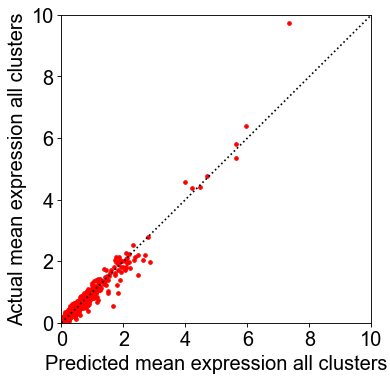

In [12]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
r_all = []
pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
predict_data = sc.read_h5ad("../experiments/plants_experiment1_predict_day21_fixed/interception_predict_to_day_21.h5ad")
real_data = sc.read_h5ad("../../inputs/plant_paper_test_day21_adata.h5ad")

r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
print(r2, pearsonr)

# r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
# print(r2_new, pearson_new)
r_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
pearsonr_all.append(['new method', "whole", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])

# pd.DataFrame(r_all).to_csv(os.path.join("new_method_r_all_new.csv"))
# pd.DataFrame(pearsonr_all).to_csv(os.path.join("new_method_pearsonr_all_new.csv"))
print(max(predict),max(real))
fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=80)
plt.scatter(predict,
            real,
             s=10,
             c='red'
           )
limit = np.ceil(max(np.max(predict), np.max(real)))

plt.xlim([0, limit])
plt.ylim([0, limit])
if limit <= 8:
  plt.xticks(np.arange(0, limit + 1, 1))
  plt.yticks(np.arange(0, limit + 1, 1)) 
else:    
  plt.xticks(np.arange(0, limit + 1, 2))
  plt.yticks(np.arange(0, limit + 1, 2))
plt.plot([0, limit], [0, limit], color="black", linestyle=":")
plt.xlabel("Predicted mean expression all clusters")
plt.ylabel("Actual mean expression all clusters")
fig.savefig(os.path.join(f"pred_with_actual_exp1_fixed_all_cluster.pdf"), bbox_inches="tight")

# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')

0 0.8113602768576296 0.9114097862919897
max 21.482143
cluster 0 done
1 0.722927836225949 0.8718563176732544
max 9.176728
cluster 1 done
2 0.8332118356808731 0.9137358764204727
max 4.8980727
cluster 2 done
3 0.6964378539046044 0.867392519133989
max 4.354957
cluster 3 done
4 0.732387993567856 0.8733005110622147
max 6.5447154
cluster 4 done
5 0.7705179427815517 0.8914002261378077
max 5.246773
cluster 5 done
6 0.3161973323219728 0.5763294589738567
max 5.947164
cluster 6 done
7 0.6657629765486119 0.8668129335036984
max 12.8131485
cluster 7 done
8 0.8037764563441129 0.9003418932829235
max 4.144558
cluster 8 done
9 0.8407347824958203 0.9187840599870899
max 5.270287
cluster 9 done
10 0.6391144265386748 0.8259134268277558
max 4.2285175
cluster 10 done
12 0.7919529908988532 0.89074201864211
max 20.48
cluster 12 done
13 0.6427099986138816 0.8064259009165137
max 5.0330787
cluster 13 done
14 0.2724395014838108 0.5382933705949868
max 4.669975
cluster 14 done


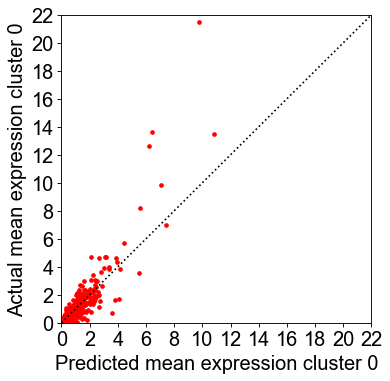

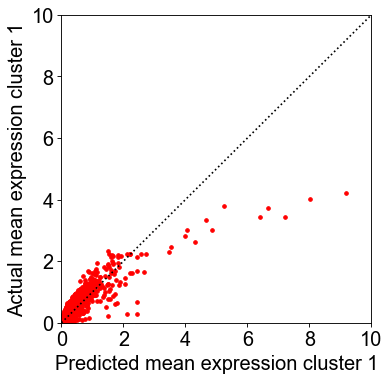

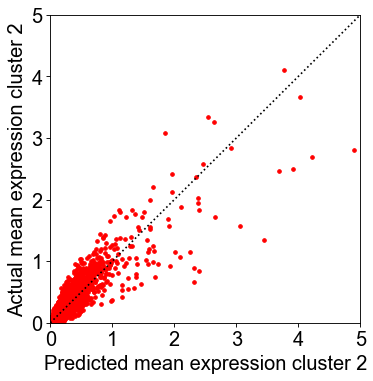

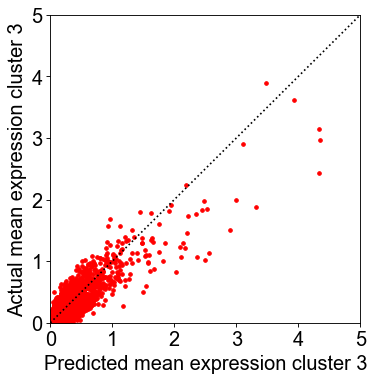

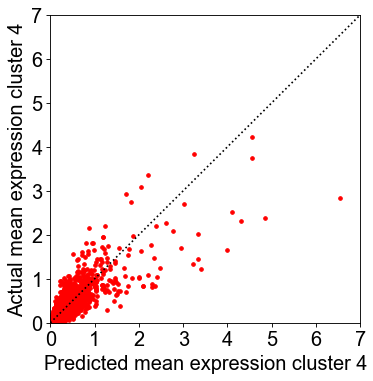

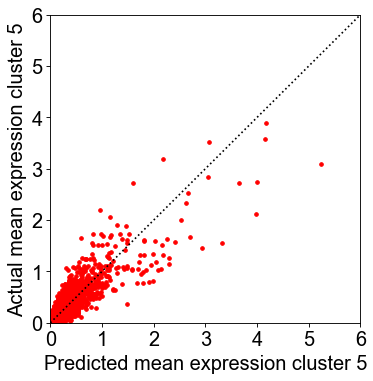

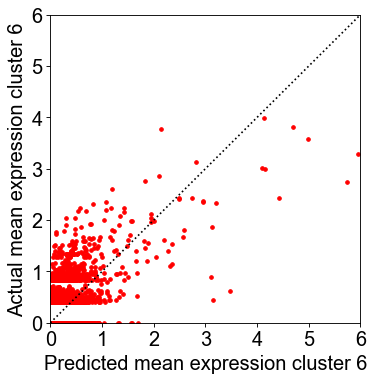

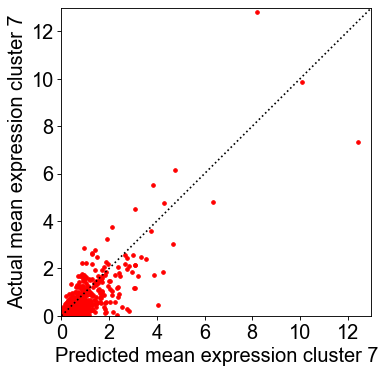

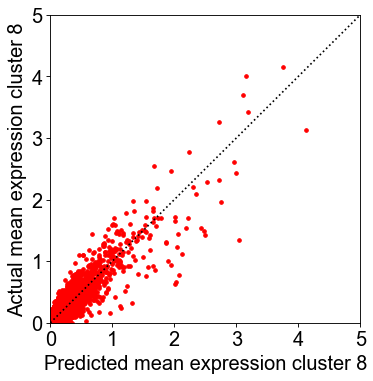

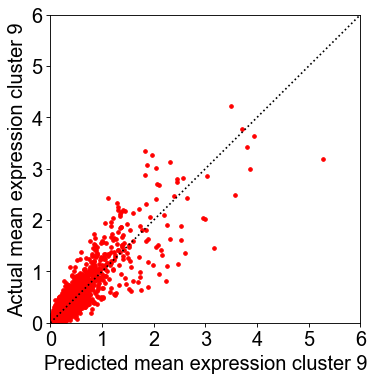

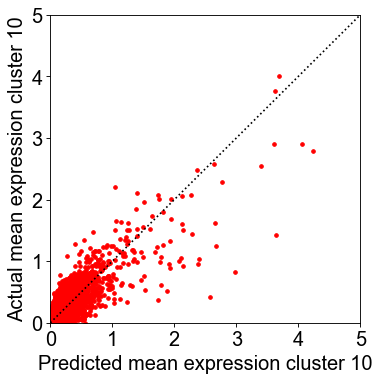

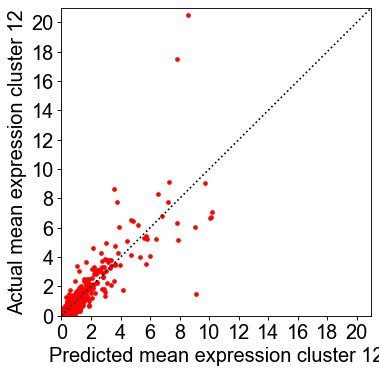

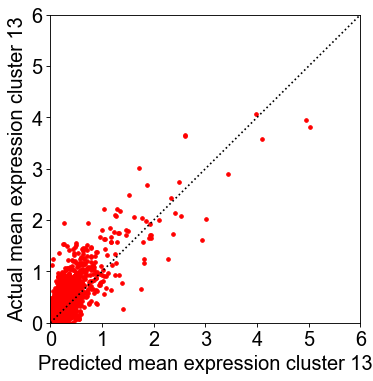

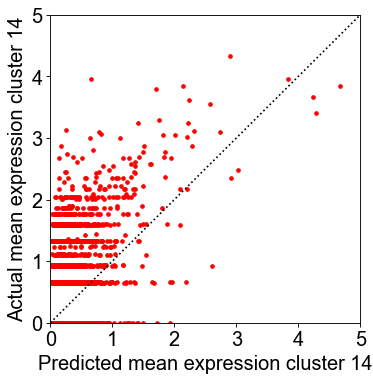

In [13]:

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
# r_all = []
# pearsonr_all = []
# print(predict_data)
# print(real_data)

# real_data_x = real_data.X if isinstance(real_data.X, np.ndarray) else real_data.X.toarray()
# real_data_tensor = torch.tensor(real_data_x, dtype=torch.float32)
# predict_data_x = predict_data.X if isinstance(predict_data.X, np.ndarray) else predict_data.X.toarray()
# predict_data_tensor = torch.tensor(predict_data_x, dtype=torch.float32)
# print(real_data_tensor.shape)
# print(predict_data_tensor.shape)
# print(real_data.shape)
for i in range(15):
  if i ==11:
    continue
  real_data = sc.read_h5ad(f"../../inputs/test_day21_plant_experiment1_cluster_{i}.h5ad")
  predict_data = sc.read_h5ad(f"../experiments/plants_experiment1_predict_day21_cluster{i}_fixed/interception_predict_to_day_21.h5ad")
  r2, pearsonr,real,predict = calc_r2_pearson(real_data,predict_data)
  print(i, r2, pearsonr)
  # r2_new, pearson_new = calc_r2_pearson(predict_data, real_data)
  # print(r2_new, pearson_new)
  r_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'r2_score:',r2])
  pearsonr_all.append(['new method', f"cluster{i}", 'predict day21 from test data day12', 'predict number:', predict_data.shape[0], 'test_data_number:',real_data.shape[0], 'pearson_score:',pearsonr])


  pd.DataFrame(r_all).to_csv(os.path.join("our_method_plant_exp1_r_all.csv"))
  pd.DataFrame(pearsonr_all).to_csv(os.path.join("our_method_plant_exp1_pearsonr_all.csv"))
  # print(max(predict),max(real))
  fig, ax = plt.subplots(1,1,figsize=(5,5),dpi=80)
  plt.scatter(predict,
              real,
              s=10,
              c='red')

  limit = np.ceil(max(np.max(predict), np.max(real)))

  plt.xlim([0, limit])
  plt.ylim([0, limit])
  if limit <= 8:
    plt.xticks(np.arange(0, limit + 1, 1))
    plt.yticks(np.arange(0, limit + 1, 1)) 
  else:    
    plt.xticks(np.arange(0, limit + 1, 2))
    plt.yticks(np.arange(0, limit + 1, 2))
  print("max",max(np.max(predict), np.max(real)))
  plt.plot([0, limit], [0, limit], color="black", linestyle=":")
  plt.xlabel(f"Predicted mean expression cluster {i}")
  plt.ylabel(f"Actual mean expression cluster {i}")
  print(f"cluster {i} done")
  fig.savefig(os.path.join(f"pred_with_actual_exp1_fixed_cluster_{i}.pdf"), bbox_inches="tight")
  # fig.savefig(os.path.join("fig2.png"), bbox_inches="tight")

# cal = calc_r2_pearson(adata_day2_predicted, adata_day2_actual)
# print(f'CAL metric: {cal}')